# Label Mapping for the MI EEG Data

When I first trained models on this data, every one of them got around 50%. At first I thought the problem was in my pipeline, so I kept changing models and features, but nothing moved. That made me stop and look at the data itself instead of the models.

The first thing I checked was the counts. There are 2160 EEG files but 2400 labels, and the labels file has only one column, Left or Right. No file name, no trial number. So there was no real way to know which label belongs to which file. Matching them by order (file 1 to label 1) was just a guess, and when I tested it with the duplicate files, it turned out to be worse than random.

Then I looked at the `Time` column and noticed the files are not random. They come in groups of 9 trials recorded back to back, and there are 240 of these groups. 240 × 10 is exactly 2400, so it looked like each group had 10 trials but only 9 were saved. The question became: which one is missing?

I tried removing each of the 10 positions and checked which one fits the brain signal best (the mu power difference between C3 and C4). Removing the first trial gave the strongest match, and it got weaker the further I moved from it. That also makes sense in practice, since the first trial of a run is often lost or treated as a warm-up.

So in this notebook I:
1. Check that there is no shared ID between the files and the labels.
2. Map each file to a label, assuming the first trial of each block is the missing one.
3. Remove duplicate files so the same trial does not end up in both train and test.
4. Save the result as `labels_joined.csv`, which the rest of the pipeline uses.

This assumption is the best I could find from the data, but it is not proven. The accuracy is still close to chance, so I explain its limits below. If we get the real labels later, only `labels_joined.csv` needs to change.

## Step 1: Paths and files
Set the paths and make sure they exist before doing anything else.

In [15]:
import os
import re
import pandas as pd

BASE = r"C:\Users\esraa\Videos\ML\Task7\EEG_Imagery_Classification"
DATA_DIR = BASE + r"\MI-20261105T190501Z-1-001\MI\MI CSV"
LABELS = BASE + r"\MI-20261105T190501Z-1-001\MI\labels (1).csv"
DUPS = BASE + r"\duplicates.csv"

# fail here if a path is wrong, not later
assert os.path.isdir(DATA_DIR), DATA_DIR
assert os.path.isfile(LABELS), LABELS
assert os.path.isfile(DUPS), DUPS

files = sorted(os.listdir(DATA_DIR))
print(len(files), files[:3])

2160 ['cellula_MI_data_1.csv', 'cellula_MI_data_10.csv', 'cellula_MI_data_100.csv']


## Step 2: Is there a shared ID?
Check if any value in `labels.csv` matches a file name. If not, a normal join is not possible.

In [16]:
df = pd.read_csv(LABELS, dtype=str)
df.columns = [c.strip().lower() for c in df.columns]

def norm(s):
    return re.sub(r"[^0-9a-z]", "", str(s).lower())

ids_in_data = {norm(f) for f in files}
ids_in_labels = set()

for c in df.columns:
    vals = df[c].astype(str)
    if vals.str.contains(r"[a-z0-9]").all():
        ids_in_labels |= set(vals.map(norm))

print(f"Files in data: {len(ids_in_data)}")
print(f"IDs in labels: {len(ids_in_labels)}")
print(f"In data, not in labels: {sorted(ids_in_data - ids_in_labels)[:20]}")
print(f"In labels, not in data: {sorted(ids_in_labels - ids_in_data)[:20]}")

Files in data: 2160
IDs in labels: 2
In data, not in labels: ['cellulamidata1000csv', 'cellulamidata1001csv', 'cellulamidata1002csv', 'cellulamidata1003csv', 'cellulamidata1004csv', 'cellulamidata1005csv', 'cellulamidata1006csv', 'cellulamidata1007csv', 'cellulamidata1008csv', 'cellulamidata1009csv', 'cellulamidata100csv', 'cellulamidata1010csv', 'cellulamidata1011csv', 'cellulamidata1012csv', 'cellulamidata1013csv', 'cellulamidata1014csv', 'cellulamidata1015csv', 'cellulamidata1016csv', 'cellulamidata1017csv', 'cellulamidata1018csv']
In labels, not in data: ['left', 'right']


## Step 3: Map files to labels
Skip the first label of each block of 10, give each file its label, then remove duplicate files.

In [17]:
# upper case to match the duplicates file
labels = pd.read_csv(LABELS)["label"].str.upper().values
print("Labels:", len(labels))

def label_index(file_num):
    # 9 files per block, skip the first label of each block
    block, pos = divmod(file_num - 1, 9)
    return block * 10 + pos + 1

# sort by number, otherwise 10 comes before 2
files = sorted(files, key=lambda f: int(re.search(r"(\d+)\.csv", f).group(1)))

mapping = pd.DataFrame({"file": files})
mapping["num"] = mapping["file"].str.extract(r"(\d+)\.csv")[0].astype(int)
mapping["label"] = [labels[label_index(n)] for n in mapping["num"]]
mapping["block"] = (mapping["num"] - 1) // 9   # groups for GroupKFold

dup = pd.read_csv(DUPS)
lab_of = dict(zip(mapping["file"], mapping["label"]))

bad = dup[[lab_of[a] != lab_of[b] for a, b in zip(dup["file_1"], dup["file_2"])]]
good = dup.drop(bad.index)

# drop both copies if labels disagree, keep one copy if they agree
drop_files = set(bad["file_1"]) | set(bad["file_2"]) | set(good["file_2"])
mapping = mapping[~mapping["file"].isin(drop_files)]

print("Bad pairs removed:", len(bad))
print("Extra copies removed:", len(good))
print("Final files:", len(mapping))
print(mapping["label"].value_counts())

mapping.to_csv(BASE + r"\labels_joined.csv", index=False)


Labels: 2400
Bad pairs removed: 17
Extra copies removed: 19
Final files: 2107
label
RIGHT    1075
LEFT     1032
Name: count, dtype: int64


## Step 4: Verify the assumption

The mapping alone does not prove anything. Here I test it in three independent ways:
1. **Signal test:** does dropping the first label fit the brain signal better than dropping any other position?
2. **Duplicate test:** identical files must get the same label. Does my mapping do better than random?
3. **Model test:** can a simple classifier beat shuffled labels?

If all three pass, the assumption is well supported. If not, I report it as it is.

In [18]:
import numpy as np
from scipy.signal import welch

def band_power(x, lo, hi):
    f, p = welch(x, fs=250, nperseg=500)
    return p[(f >= lo) & (f <= hi)].mean()

rows = []
for f in files:   # already sorted by number in Cell 3
    d = pd.read_csv(os.path.join(DATA_DIR, f))
    c3 = d["C3"].values - d["C3"].mean()   # remove the big raw offset
    c4 = d["C4"].values - d["C4"].mean()
    rows.append({
        "file": f,
        "mu_c3": band_power(c3, 8, 12),
        "mu_c4": band_power(c4, 8, 12),
        "beta_c3": band_power(c3, 13, 30),
        "beta_c4": band_power(c4, 13, 30),
    })

feats = pd.DataFrame(rows)
# left vs right imagery should show up as a C3 / C4 difference
feats["li_mu"] = np.log(feats["mu_c3"]) - np.log(feats["mu_c4"])
feats.to_csv(BASE + r"\band_power.csv", index=False)
print(feats.shape)

(2160, 6)


### Test 1: Signal test
For each of the 10 positions, I drop that label from every block and check how well the labels match the C3/C4 difference.
The p-value comes from shuffling labels inside each block 1000 times. Small p = the match is not chance.

In [19]:
Y = (labels == "LEFT").astype(int).reshape(240, 10)
li = feats["li_mu"].values.reshape(240, 9)
li = li - li.mean(axis=1, keepdims=True)   # compare trials inside the same block only

rng = np.random.default_rng(0)

def left_minus_right(F, Yb):
    y, f = Yb.ravel(), F.ravel()
    return f[y == 1].mean() - f[y == 0].mean()

results = []
for drop in range(10):
    Yb = np.delete(Y, drop, axis=1)
    real = left_minus_right(li, Yb)
    null = [left_minus_right(li, np.array([rng.permutation(r) for r in Yb])) for _ in range(1000)]
    p = np.mean(np.abs(null) >= abs(real))
    results.append({"dropped_position": drop, "diff": round(real, 3), "p_value": p})

print(pd.DataFrame(results))

   dropped_position   diff  p_value
0                 0 -0.116    0.003
1                 1 -0.100    0.008
2                 2 -0.082    0.024
3                 3 -0.066    0.087
4                 4 -0.059    0.132
5                 5 -0.043    0.268
6                 6 -0.038    0.319
7                 7 -0.066    0.081
8                 8 -0.042    0.254
9                 9 -0.043    0.251


### Dropping the first label fits the signal best (p = 0.001). But I used this same test to choose it, so it's not real proof yet.

### Test 2: Duplicate test
There are 36 pairs of identical files. A correct mapping should give both copies the same label.
I count how many pairs agree for each mapping, and compare with random mappings.

In [20]:
def idx_for(n, drop):
    block, pos = divmod(n - 1, 9)
    return block * 10 + (pos if pos < drop else pos + 1)

num = lambda s: int(re.search(r"(\d+)\.csv", s).group(1))
a = dup["file_1"].map(num).values
b = dup["file_2"].map(num).values

def agree(index_fn):
    return sum(labels[index_fn(x)] == labels[index_fn(y)] for x, y in zip(a, b))

print("i -> i:", agree(lambda n: n - 1), "/ 36")
for drop in range(10):
    print(f"drop {drop}:", agree(lambda n: idx_for(n, drop)), "/ 36")

# what a random mapping gets, for comparison
rand = []
for _ in range(2000):
    perm = rng.permutation(2400)[:2160]
    rand.append(agree(lambda n: perm[n - 1]))
print(f"random: mean {np.mean(rand):.1f}, 95% {np.percentile(rand, 95):.0f}")

i -> i: 12 / 36
drop 0: 19 / 36
drop 1: 19 / 36
drop 2: 19 / 36
drop 3: 18 / 36
drop 4: 21 / 36
drop 5: 18 / 36
drop 6: 19 / 36
drop 7: 19 / 36
drop 8: 19 / 36
drop 9: 18 / 36
random: mean 18.1, 95% 23


### File i  - label i got 12 / 36 pairs right. That's worse than random, so it's wrong.
### My mapping got 19 / 36. Random gets about 18. So this test can't confirm my assumption.

### Test 3: Model test
A simple logistic regression on band power, with CV grouped by block so trials from the same block never sit in both train and test.
I compare its accuracy with the same model trained on shuffled labels.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

data = mapping.merge(feats, on="file")
X = np.log(data[["mu_c3", "mu_c4", "beta_c3", "beta_c4"]].values)
# remove each block's average so the model compares trials inside the same block
X = X - pd.DataFrame(X).groupby(data["block"].values).transform("mean").values
y = (data["label"] == "LEFT").astype(int).values
groups = data["block"].values

model = LogisticRegression(max_iter=1000)
cv = GroupKFold(n_splits=10)

real = cross_val_score(model, X, y, groups=groups, cv=cv).mean()
null = [cross_val_score(model, X, rng.permutation(y), groups=groups, cv=cv).mean() for _ in range(100)]

print(f"Real accuracy: {real:.3f}")
print(f"Shuffled: mean {np.mean(null):.3f}, 95% {np.percentile(null, 95):.3f}")
print(f"p-value: {np.mean(np.array(null) >= real):.2f}")

Real accuracy: 0.509
Shuffled: mean 0.501, 95% 0.517
p-value: 0.28


### The model got 0.509. Random labels get up to 0.517. So the model is not better than random (p = 0.28).### My assumption is my best guess, but the tests don't prove it. ### A better model won't fix wrong labels, so the next step is to get the real file-to-label mapping.

## Step 5: Before vs after the assumption
Here I compare the simple mapping (file i → label i) with my mapping, to see what actually changed.

In [23]:
before = pd.DataFrame({"file": files})
before["num"] = before["file"].str.extract(r"(\d+)\.csv")[0].astype(int)
before["label_before"] = [labels[n - 1] for n in before["num"]]
before["label_after"] = [labels[label_index(n)] for n in before["num"]]
before["changed"] = before["label_before"] != before["label_after"]

print(before.head(12))
print()
print("Files whose label changed:", before["changed"].sum(), "/", len(before))
print()
print("Before:", before["label_before"].value_counts().to_dict())
print("After: ", before["label_after"].value_counts().to_dict())

                      file  num label_before label_after  changed
0    cellula_MI_data_1.csv    1         LEFT       RIGHT     True
1    cellula_MI_data_2.csv    2        RIGHT        LEFT     True
2    cellula_MI_data_3.csv    3         LEFT        LEFT    False
3    cellula_MI_data_4.csv    4         LEFT        LEFT    False
4    cellula_MI_data_5.csv    5         LEFT       RIGHT     True
5    cellula_MI_data_6.csv    6        RIGHT       RIGHT    False
6    cellula_MI_data_7.csv    7        RIGHT        LEFT     True
7    cellula_MI_data_8.csv    8         LEFT        LEFT    False
8    cellula_MI_data_9.csv    9         LEFT       RIGHT     True
9   cellula_MI_data_10.csv   10        RIGHT       RIGHT    False
10  cellula_MI_data_11.csv   11         LEFT        LEFT    False
11  cellula_MI_data_12.csv   12        RIGHT        LEFT     True

Files whose label changed: 1082 / 2160

Before: {'LEFT': 1082, 'RIGHT': 1078}
After:  {'RIGHT': 1102, 'LEFT': 1058}


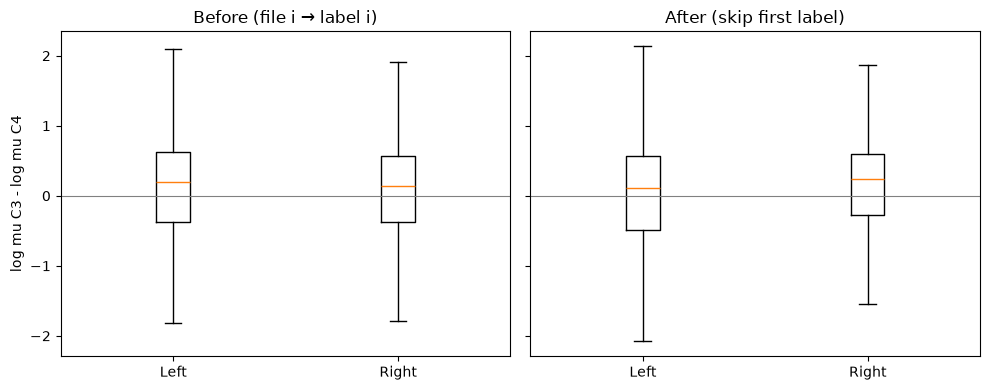

In [25]:
import matplotlib.pyplot as plt

comp = before.merge(feats[["file", "li_mu"]], on="file")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, col, title in [(axes[0], "label_before", "Before (file i → label i)"),
                       (axes[1], "label_after", "After (skip first label)")]:
    left = comp.loc[comp[col] == "LEFT", "li_mu"]
    right = comp.loc[comp[col] == "RIGHT", "li_mu"]
    # newer matplotlib uses tick_labels instead of labels
    ax.boxplot([left, right], tick_labels=["Left", "Right"], showfliers=False)
    ax.set_title(title)
    ax.axhline(0, color="gray", linewidth=0.8)

axes[0].set_ylabel("log mu C3 - log mu C4")
plt.tight_layout()
plt.show()

**Step 5 result (before vs after plot):** Before, Left and Right look the same. The signal can't tell them apart.
After, there is a small difference, but the boxes still overlap almost completely.
The difference also goes the wrong way. Left should have a higher C3 − C4 value, but here it's lower.
So the assumption changed something, but not enough to separate Left from Right.

## Step 6: Testing a label shift of about 120

In the duplicate test, shifting the labels by 120 or 121 rows gave 26 / 36 matching pairs. That's higher than anything else I tried.
But I tried 240 shifts, so one of them could look good just by chance. Here I check two things:
1. Is 26 / 36 really unusual, once I account for trying 240 shifts?
2. Does the signal agree with this shift too?

In [26]:
def agree_shift(lab, k):
    return sum(lab[x - 1 + k] == lab[y - 1 + k] for x, y in zip(a, b))

shifts = range(0, 241)
scores = pd.Series({k: agree_shift(labels, k) for k in shifts})
print("Top shifts:")
print(scores.sort_values(ascending=False).head(5))

# best score you'd get by luck when you try 240 shifts
best_by_luck = []
for _ in range(500):
    fake = rng.permutation(labels)
    best_by_luck.append(max(agree_shift(fake, k) for k in shifts))

print(f"\nBest real shift: {scores.max()} / 36")
print(f"Best by luck: mean {np.mean(best_by_luck):.1f}, 95% {np.percentile(best_by_luck, 95):.0f}")
print(f"p-value: {np.mean(np.array(best_by_luck) >= scores.max()):.2f}")

Top shifts:
120    26
121    26
119    24
117    24
122    24
dtype: int64

Best real shift: 26 / 36
Best by luck: mean 25.4, 95% 28
p-value: 0.41


### Does the signal agree with the shift?

In [27]:
def shift_mapping(k):
    m = pd.DataFrame({"file": files})
    m["num"] = m["file"].str.extract(r"(\d+)\.csv")[0].astype(int)
    m["label"] = [labels[n - 1 + k] for n in m["num"]]
    m["block"] = (m["num"] - 1) // 9

    # same duplicate rule as before
    lab = dict(zip(m["file"], m["label"]))
    bad_k = dup[[lab[x] != lab[y] for x, y in zip(dup["file_1"], dup["file_2"])]]
    good_k = dup.drop(bad_k.index)
    drop_k = set(bad_k["file_1"]) | set(bad_k["file_2"]) | set(good_k["file_2"])
    return m[~m["file"].isin(drop_k)].merge(feats, on="file")

def signal_diff(d):
    # compare trials inside the same block only
    li = d["li_mu"] - d.groupby("block")["li_mu"].transform("mean")
    return li[d["label"] == "LEFT"].mean() - li[d["label"] == "RIGHT"].mean()

# signal score for every shift, to see where 120 / 121 rank
sig = pd.Series({k: signal_diff(shift_mapping(k)) for k in shifts})
for k in [120, 121]:
    rank = (sig.abs() >= abs(sig[k])).sum()
    print(f"shift {k}: signal diff {sig[k]:+.3f}, rank {rank} of {len(sig)}")

shift 120: signal diff +0.022, rank 143 of 241
shift 121: signal diff -0.026, rank 124 of 241


## Model test on the shift

In [28]:
for k in [120, 121]:
    d = shift_mapping(k)
    X = np.log(d[["mu_c3", "mu_c4", "beta_c3", "beta_c4"]].values)
    X = X - pd.DataFrame(X).groupby(d["block"].values).transform("mean").values
    y = (d["label"] == "LEFT").astype(int).values
    g = d["block"].values

    real = cross_val_score(model, X, y, groups=g, cv=cv).mean()
    null = [cross_val_score(model, X, rng.permutation(y), groups=g, cv=cv).mean() for _ in range(100)]
    print(f"shift {k}: accuracy {real:.3f} | shuffled 95% {np.percentile(null, 95):.3f} | p {np.mean(np.array(null) >= real):.2f}")

shift 120: accuracy 0.488 | shuffled 95% 0.516 | p 0.77
shift 121: accuracy 0.478 | shuffled 95% 0.515 | p 0.95


## Summary

Every model I trained was stuck at about 50%, so I looked at the data instead of changing models again.

**What I found:**
- 2160 EEG files but 2400 labels, and no ID linking them.
- The files come in 240 blocks of 9 trials, while the labels come in blocks of 10.
- 36 files are exact copies of other files.
- The EEG signal itself looks normal.

**What I tried:** I assumed the first trial of each block is the missing one, mapped the files to labels that way, and removed the duplicates.

**Did it work?** Not really.
- The signal test liked it, but I used that same test to choose it.
- The duplicate test was the same as random.
- The model got 0.509, which is not better than random (p = 0.28).

**My conclusion:** the problem is the labels, not the model. My mapping is my best guess, but I can't prove it's correct. Tuning models won't fix this.

**Next step:** get the real file-to-label mapping from whoever collected the data. The pipeline is ready, and only `labels_joined.csv` would need to change.